In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(x_train.shape)

(60000, 28, 28)


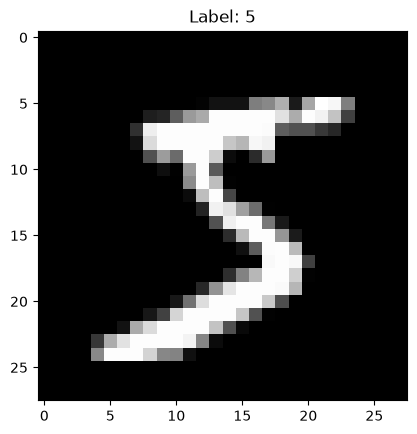

In [4]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.show()

In [5]:
nsamples_train, nx, ny = x_train.shape
x_train_2d = x_train.reshape((nsamples_train, nx * ny)).astype('float32')

nsamples_test, nx_test, ny_test = x_test.shape
x_test_2d = x_test.reshape((nsamples_test, nx_test * ny_test)).astype('float32')


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train_2d) 
X_test_scaled = scaler.transform(x_test_2d)

In [7]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

In [8]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    data_augmentation, 

    tf.keras.layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10)
])

In [19]:
# model = tf.keras.models.Sequential([
#     tf.keras.Input(shape=(28,28)),
#     tf.keras.layers.Flatten(),
#     tf.keras.layers.Dense(128, activation='relu'),
#     tf.keras.layers.Dense(10),
# ])

In [9]:
model.compile(
    optimizer='adam',
    # Use SparseCategoricalCrossentropy when labels are integers (0-9)
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


In [10]:
# Train the model for 5 epochs
model.fit(x_train, y_train, epochs=10)

# Evaluate performance on test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_acc:.4f}")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8650 - loss: 0.5241
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9459 - loss: 0.1836
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9549 - loss: 0.1501
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9620 - loss: 0.1283
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9675 - loss: 0.1108
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9696 - loss: 0.1044
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9719 - loss: 0.0975
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9727 - loss: 0.0945
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9733 - loss: 0.0911
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9745 - loss: 0.0885
313/313 - 0s - 1ms/step - accuracy: 0.9796 - loss: 0.0840

Test accuracy: 0.9796


In [17]:
index = 10

prediction = model.predict(np.expand_dims(x_train[index], axis=0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


Raw prediction: [[-16.51675     -6.160452   -11.735654    32.160088   -15.861755
   12.451355   -25.506172    -0.86918247  -2.1559238    1.5477577 ]]
Predicted digit: 3
Actual digit: 3


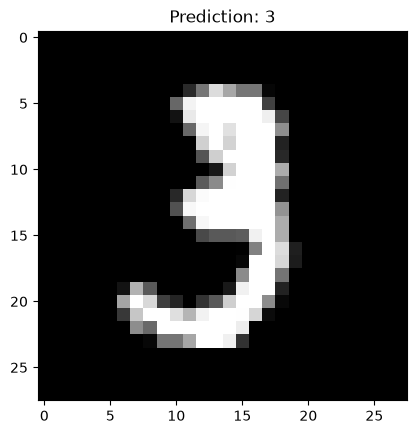

In [18]:
print("Raw prediction:", prediction)
print("Predicted digit:", np.argmax(prediction))
print("Actual digit:", y_train[index])

plt.imshow(x_train[index], cmap="gray")
plt.title(f"Prediction: {np.argmax(prediction)}")
plt.show()

In [20]:
model.save("mnist_modelv3.keras")
